Loading Bank Marketing Dataset...

Dataset Loaded Successfully!
Dataset Shape: (45211, 17)

First Five Rows:
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married        NaN      no     1506     yes   no   
4   33           NaN   single        NaN      no        1      no   no   

  contact  day_of_week month  duration  campaign  pdays  previous poutcome   y  
0     NaN            5   may       261         1     -1         0      NaN  no  
1     NaN            5   may       151         1     -1         0      NaN  no  
2     NaN            5   may        76         1     -1         0      NaN  no  
3     NaN            5   may        92         1     -1         0      NaN  no  
4     NaN            5   may       198   

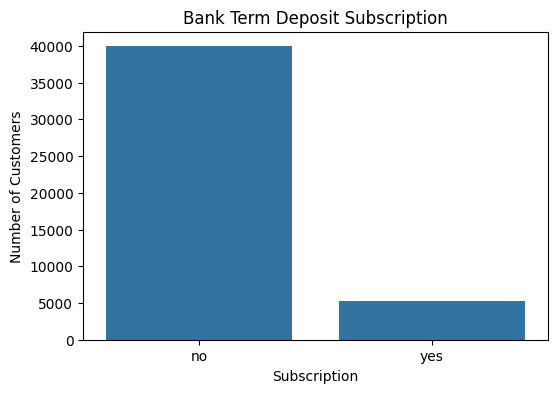

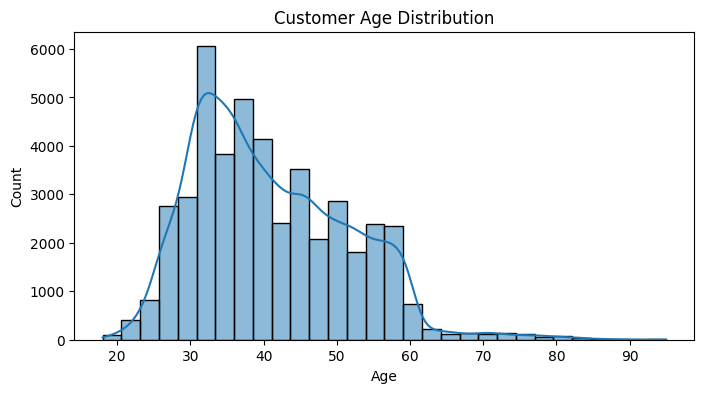


Numerical Features: ['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous']

Categorical Features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Training Data: (36168, 16)
Testing Data: (9043, 16)

AdaBoost
Accuracy: 89.52 %

Classification Report:
              precision    recall  f1-score   support

          No       0.91      0.98      0.94      7985
         Yes       0.65      0.22      0.33      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.60      0.64      9043
weighted avg       0.88      0.90      0.87      9043



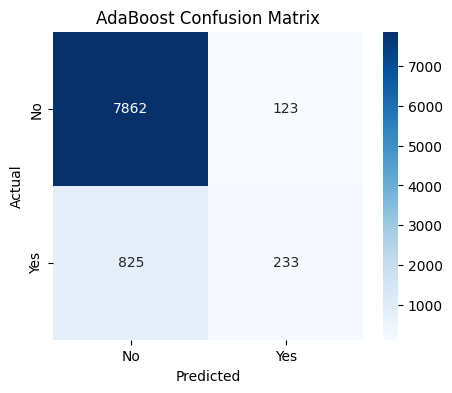


Gradient Boosting
Accuracy: 90.59 %

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.97      0.95      7985
         Yes       0.66      0.40      0.50      1058

    accuracy                           0.91      9043
   macro avg       0.79      0.69      0.72      9043
weighted avg       0.89      0.91      0.90      9043



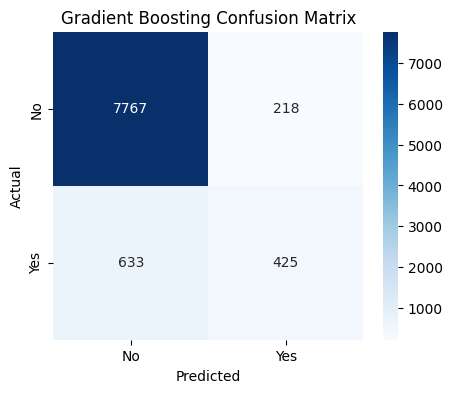


========== MODEL COMPARISON ==========
AdaBoost Accuracy: 89.52 %
Gradient Boosting Accuracy: 90.59 %


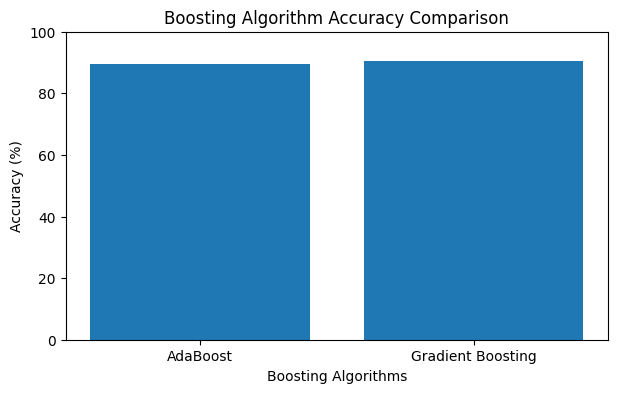


Best Performing Model: Gradient Boosting
Best Accuracy: 90.59 %

BOOSTING PROJECT COMPLETED SUCCESSFULLY!


In [2]:
# ==========================================
# BOOSTING MACHINE LEARNING PROJECT
# Bank Marketing Dataset
# ==========================================

#  Install required library
!pip install -q ucimlrepo

#  Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

#  Load Bank Marketing Dataset
print("Loading Bank Marketing Dataset...")

bank_marketing = fetch_ucirepo(id=222)

X = bank_marketing.data.features
y = bank_marketing.data.targets

# Combine features and target
df = pd.concat([X, y], axis=1)

# Remove rows with missing target values
target = y.iloc[:, 0]
valid = target.notna()

X = X.loc[valid].copy()
y = target.loc[valid].copy()

print("\nDataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

#  Display Dataset Information
print("\nFirst Five Rows:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:", df.duplicated().sum())

#  Data Visualization

plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title("Bank Term Deposit Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.show()

plt.figure(figsize=(8, 4))
sns.histplot(X["age"], bins=30, kde=True)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.show()

#  Separate Numerical and Categorical Columns

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

#  Data Preprocessing

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

#  Convert Target Values into 0 and 1

y = y.astype(str).str.strip().str.lower().map({
    "no": 0,
    "yes": 1
})

# Remove any invalid target values
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid].astype(int)

#  Split Dataset into Training and Testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

#  Create Boosting Models

models = {
    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

results = {}

#  Train and Test Models

for name, model in models.items():

    print("\n================================")
    print(name)
    print("================================")

    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict output
    y_pred = pipeline.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy

    print("Accuracy:", round(accuracy * 100, 2), "%")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No", "Yes"],
        zero_division=0
    ))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"]
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    # Store trained pipeline
    models[name] = pipeline

#  Compare Boosting Algorithms

print("\n========== MODEL COMPARISON ==========")

for name, accuracy in results.items():
    print(name, "Accuracy:", round(accuracy * 100, 2), "%")

# Accuracy Comparison Graph

plt.figure(figsize=(7, 4))

plt.bar(
    results.keys(),
    [value * 100 for value in results.values()]
)

plt.title("Boosting Algorithm Accuracy Comparison")
plt.xlabel("Boosting Algorithms")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()

#  Find Best Performing Model

best_model_name = max(results, key=results.get)

print("\nBest Performing Model:", best_model_name)
print("Best Accuracy:", round(
    results[best_model_name] * 100, 2
), "%")

print("\nBOOSTING PROJECT COMPLETED SUCCESSFULLY!")